# 02 — Poisson-process model of Severe pollution days

**Part:** Member A — Poisson process (estimation, checks, extensions, simulation, out-of-sample test)

**Question.** *How often do Severe air-quality days (daily PM2.5 > 250 µg/m³) occur in Delhi, does the rate
depend on the season or the year, and can a Poisson process describe them?*

## Mathematical formulation

| Item | Choice |
|---|---|
| Time parameter | $t \ge 0$, measured in days (continuous); data are recorded per day, $d = 1,2,\dots$ |
| Event | a day with mean PM2.5 $> c = 250$ µg/m³ ("Severe", CPCB) |
| Counting process | $N(t)$ = number of Severe days in $(0, t]$ |
| State space | $\{0, 1, 2, \dots\}$ |
| Random variables | $N(t)$; inter-arrival times $X_k = S_k - S_{k-1}$; episode lengths $L_i$ |
| Exposure | only valid (observed or interpolated) days count; a missing day carries no information |

**Model 1 — homogeneous Poisson process (HPP), rate $\lambda$.** Assumptions: $N(0)=0$; independent increments;
stationary increments; at most one event in a short interval. Consequences:

$$P\{N(t)=k\} = e^{-\lambda t}\frac{(\lambda t)^k}{k!},\qquad E[N(t)] = \operatorname{Var}[N(t)] = \lambda t,\qquad X_k \stackrel{iid}{\sim}\text{Exp}(\lambda),\ E[X_k]=1/\lambda .$$

**Model 2 — non-homogeneous Poisson process (NHPP).** The rate depends on the calendar month,
$\lambda(t) = \lambda_{m(t)}$, $m = 1,\dots,12$. Independent increments still hold, and
$N(t) \sim \text{Poisson}(\Lambda(t))$ with $\Lambda(t) = \int_0^t \lambda(s)\,ds$.

**Model 3 — compound (clustered) Poisson process.** *Episodes* (runs of consecutive Severe days) start as an
NHPP with rate $\mu_{m(t)}$ and each lasts $L_i \stackrel{iid}{\sim}$ Geometric$(1-q)$ days:
$N(t) = \sum_{i=1}^{K(t)} L_i$. Then $E[N(t)] = \Lambda_\mu(t)\,E[L]$ and $\operatorname{Var}[N(t)] = \Lambda_\mu(t)\,E[L^2]$.

**Estimation (maximum likelihood).** For a Poisson process observed for exposure $T$ with $n$ events,
the log-likelihood is $\ell(\lambda) = n\log\lambda - \lambda T$, so $\hat\lambda = n/T$.
An exact 95 % confidence interval comes from the Poisson–chi-square relation (Garwood):
$\left[\tfrac{1}{2T}\chi^2_{0.025,\,2n},\ \tfrac{1}{2T}\chi^2_{0.975,\,2n+2}\right]$.
For the NHPP the same applies separately to each month: $\hat\lambda_m = n_m / T_m$.

*Note on daily data.* The data record whether a day was Severe, not exact event times, so at most one event
per day is seen. When the rate is small (a few % per day) a Bernoulli day-by-day process is well approximated
by a Poisson process (law of rare events); for continuous-time checks an event is placed at a uniform random
time within its day.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

CLEAN = Path("../data/clean")
FIG = Path("../figures")
RES = Path("../results")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
rng = np.random.default_rng(2026)

THRESH = 250            # event threshold (µg/m³)
TRAIN_END = "2022-12-31"
N_SIM = 2000
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
SEASONS = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
RESULTS = {"threshold": THRESH}

df = pd.read_csv(CLEAN / "delhi_rkpuram_daily.csv", parse_dates=["date"], index_col="date")
df["valid"] = df.status != "missing"
df["event"] = df.valid & (df.pm25 > THRESH)
study = df[df.period == "study"].copy()
holdout = df[df.period == "holdout"].copy()
print(f"study: {study.index.min().date()} -> {study.index.max().date()}, valid days = {study.valid.sum()}, "
      f"Severe days = {study.event.sum()}")

study: 2016-01-01 -> 2025-12-31, valid days = 3430, Severe days = 300


### Helper functions

In [2]:
def rate_ci(n, T, alpha=0.05):
    """MLE of a Poisson rate and its exact (Garwood) confidence interval."""
    lo = 0.0 if n == 0 else stats.chi2.ppf(alpha / 2, 2 * n) / 2
    hi = stats.chi2.ppf(1 - alpha / 2, 2 * n + 2) / 2
    return n / T, lo / T, hi / T


def cell_table(d, col="event"):
    """Counts and exposure (valid days) for every (year, month) cell."""
    t = d.groupby(["year", "month"]).agg(n=(col, "sum"), T=("valid", "sum")).reset_index()
    return t[t["T"] > 0].reset_index(drop=True)


def pearson_dispersion(n, mu, n_params):
    """Pearson X^2 / df. Equals about 1 if counts are Poisson with means mu.
    Cells with a fitted mean of 0 (months whose estimated rate is 0) carry no information,
    so they are dropped; n_params counts only the non-zero rate parameters."""
    n, mu = np.asarray(n, float), np.asarray(mu, float)
    keep = mu > 0
    x2 = float(np.sum((n[keep] - mu[keep]) ** 2 / mu[keep]))
    dof = int(keep.sum()) - n_params
    return x2 / dof, x2, dof, float(stats.chi2.sf(x2, dof))


def n_active(rates):
    """Number of non-zero rate parameters."""
    return sum(v > 0 for v in rates.values())


def rescaled_times(d, rate_by_month, event_col):
    """Time-rescaling theorem: Lambda(S_k) for each event (uniform position within the day).
    If the model is right, the gaps between successive values are iid Exp(1)."""
    lam_d = d.month.map(rate_by_month).to_numpy() * d.valid.to_numpy()
    L_end = np.cumsum(lam_d)
    pos = np.flatnonzero(d[event_col].to_numpy())
    u = rng.uniform(size=len(pos))
    return L_end[pos] - lam_d[pos] * (1 - u)


def exp_qq(ax, tau, label, color):
    tau = np.sort(tau)
    q = -np.log(1 - (np.arange(1, len(tau) + 1) - 0.5) / len(tau))
    ax.plot(q, tau, ".", ms=3, color=color, label=label)

## 1. Homogeneous Poisson process

In [3]:
N, T = int(study.event.sum()), int(study.valid.sum())
lam, lam_lo, lam_hi = rate_ci(N, T)
print(f"N = {N} Severe days over T = {T} valid days")
print(f"lambda_hat = {lam:.4f} per day   95% CI [{lam_lo:.4f}, {lam_hi:.4f}]")
print(f"           = {lam * 365.25:.1f} per year   95% CI [{lam_lo * 365.25:.1f}, {lam_hi * 365.25:.1f}]")
print(f"mean waiting time 1/lambda = {1 / lam:.1f} days")
print(f"P(no Severe day in 30 days) = exp(-30 lambda) = {np.exp(-30 * lam):.3f}")
print(f"P(at least one Severe day in a week) = {1 - np.exp(-7 * lam):.3f}")
RESULTS["hpp"] = {"N": N, "T": T, "lambda_day": lam, "ci_day": [lam_lo, lam_hi],
                  "lambda_year": lam * 365.25, "ci_year": [lam_lo * 365.25, lam_hi * 365.25],
                  "mean_wait_days": 1 / lam}

N = 300 Severe days over T = 3430 valid days
lambda_hat = 0.0875 per day   95% CI [0.0778, 0.0979]
           = 31.9 per year   95% CI [28.4, 35.8]
mean waiting time 1/lambda = 11.4 days
P(no Severe day in 30 days) = exp(-30 lambda) = 0.073
P(at least one Severe day in a week) = 0.458


### 1a. Does the HPP fit? — monthly counts
Under the HPP the count in a (year, month) cell with $T_{ym}$ valid days is Poisson$(\lambda T_{ym})$,
so the mean equals the variance. The **dispersion index** (Pearson $X^2$/df) should then be ≈ 1.

monthly counts: mean = 2.50, variance = 21.43
HPP dispersion index = 8.11  (X2 = 965, df = 119, p = 1.7e-132)


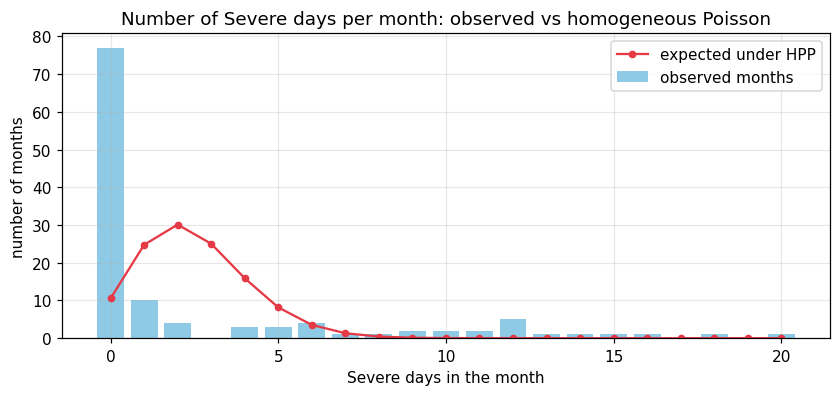

In [4]:
cells = cell_table(study)
cells["mu_hpp"] = lam * cells["T"]
D_hpp, X2_hpp, df_hpp, p_hpp = pearson_dispersion(cells.n, cells.mu_hpp, 1)
print(f"monthly counts: mean = {cells.n.mean():.2f}, variance = {cells.n.var():.2f}")
print(f"HPP dispersion index = {D_hpp:.2f}  (X2 = {X2_hpp:.0f}, df = {df_hpp}, p = {p_hpp:.1e})")
RESULTS["hpp"].update({"monthly_mean": cells.n.mean(), "monthly_var": cells.n.var(),
                       "dispersion": D_hpp, "dispersion_p": p_hpp})

kmax = int(cells.n.max())
k = np.arange(kmax + 1)
obs_freq = np.bincount(cells.n, minlength=kmax + 1)
exp_freq = np.array([stats.poisson.pmf(kk, cells.mu_hpp).sum() for kk in k])
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(k, obs_freq, color="#8ecae6", label="observed months")
ax.plot(k, exp_freq, "o-", color="#e63946", ms=4, label="expected under HPP")
ax.set(title="Number of Severe days per month: observed vs homogeneous Poisson",
       xlabel="Severe days in the month", ylabel="number of months")
ax.legend()
fig.savefig(FIG / "A06_monthly_counts_vs_hpp.png")
plt.show()

### 1b. Inter-arrival times
Gaps between consecutive Severe days (only gaps with no missing days in between).
Under the HPP they are Exponential(λ) — or Geometric(λ) on a daily grid — with mean $1/\hat\lambda$.

284 gaps: mean = 5.6 days (HPP predicts 11.4), median = 1, sd = 25.0
share of gaps equal to 1 day: observed 0.66, Geometric model 0.09
KS test vs Exp(lambda): D = 0.584, p = 9.4e-93


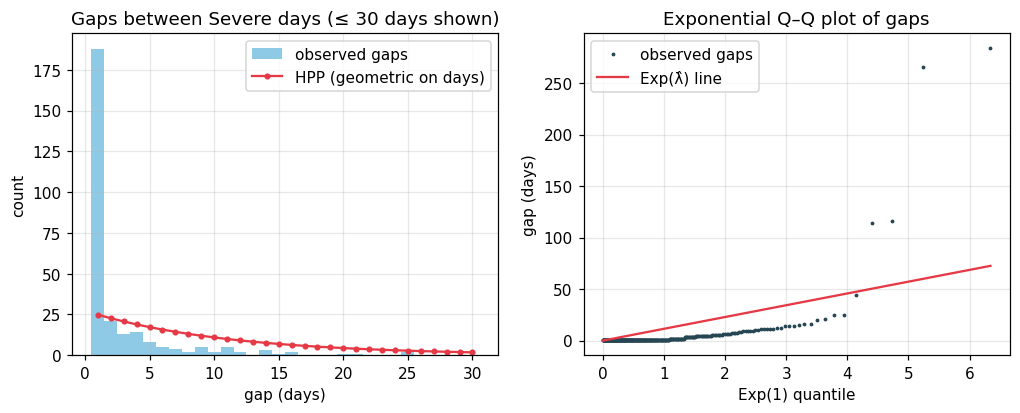

In [5]:
ev_days = study.index[study.event]
gaps = np.diff(ev_days).astype("timedelta64[D]").astype(int)
miss_cum = (~study.valid).cumsum()
clean_gap = (miss_cum.loc[ev_days[1:]].to_numpy() - miss_cum.loc[ev_days[:-1]].to_numpy()) == 0
gaps = gaps[clean_gap]
print(f"{len(gaps)} gaps: mean = {gaps.mean():.1f} days (HPP predicts {1 / lam:.1f}), "
      f"median = {np.median(gaps):.0f}, sd = {gaps.std(ddof=1):.1f}")
print(f"share of gaps equal to 1 day: observed {np.mean(gaps == 1):.2f}, Geometric model {lam:.2f}")
ks_gap = stats.kstest(gaps - rng.uniform(size=len(gaps)), "expon", args=(0, 1 / lam))
print(f"KS test vs Exp(lambda): D = {ks_gap.statistic:.3f}, p = {ks_gap.pvalue:.1e}")
RESULTS["gaps"] = {"n": len(gaps), "mean": gaps.mean(), "median": float(np.median(gaps)),
                   "share_1day": float(np.mean(gaps == 1)), "ks_D": ks_gap.statistic, "ks_p": ks_gap.pvalue}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
bins = np.arange(0.5, 31.5)
ax.hist(gaps[gaps <= 30], bins=bins, color="#8ecae6", label="observed gaps")
kk = np.arange(1, 31)
ax.plot(kk, len(gaps) * lam * (1 - lam) ** (kk - 1), "o-", ms=3, color="#e63946", label="HPP (geometric on days)")
ax.set(title="Gaps between Severe days (≤ 30 days shown)", xlabel="gap (days)", ylabel="count")
ax.legend()
ax = axes[1]
exp_qq(ax, gaps, "observed gaps", "#264653")
q = np.linspace(0, -np.log(0.5 / len(gaps)), 50)
ax.plot(q, q / lam, color="#e63946", label="Exp(λ̂) line")
ax.set(title="Exponential Q–Q plot of gaps", xlabel="Exp(1) quantile", ylabel="gap (days)")
ax.legend()
fig.savefig(FIG / "A07_interarrival.png")
plt.show()

**Reading.** If the HPP were right, monthly counts would have variance ≈ mean and gaps would be exponential.
Instead (see numbers above) the variance is many times the mean, there are far too many 1-day gaps
(Severe days come back-to-back) and far too many very long gaps (the whole summer and monsoon).
Two different effects are mixed: **seasonality** and **clustering**. We model them one at a time.

## 2. Seasonal (non-homogeneous) Poisson process

In [6]:
def rates_by(d, key, levels):
    rows = []
    for lev in levels:
        s = d[d[key] == lev]
        n_, T_ = int(s.event.sum()), int(s.valid.sum())
        r, lo, hi = rate_ci(n_, T_)
        rows.append({key: lev, "events": n_, "valid_days": T_, "rate_per_day": r, "ci_lo": lo, "ci_hi": hi})
    return pd.DataFrame(rows).set_index(key)

month_rates = rates_by(study, "month", range(1, 13))
season_rates = rates_by(study, "season", SEASONS)
month_rates.index = MONTHS
month_rates["expected per month"] = month_rates.rate_per_day * 30.4
season_rates["expected per year"] = season_rates.rate_per_day * study.groupby("season").size() / 10
display(month_rates.round(4))
display(season_rates.round(4))

,events,valid_days,rate_per_day,ci_lo,ci_hi,expected per month
Jan,85,287,0.2962,0.2366,0.3662,9.0035
Feb,5,272,0.0184,0.0060,0.0429,0.5588
Mar,0,286,0.0000,0.0000,0.0129,0.0000
Apr,0,258,0.0000,0.0000,0.0143,0.0000
May,3,294,0.0102,0.0021,0.0298,0.3102
Jun,0,288,0.0000,0.0000,0.0128,0.0000
Jul,0,277,0.0000,0.0000,0.0133,0.0000
Aug,0,286,0.0000,0.0000,0.0129,0.0000
Sep,0,299,0.0000,0.0000,0.0123,0.0000
Oct,11,286,0.0385,0.0192,0.0688,1.1692


,events,valid_days,rate_per_day,ci_lo,ci_hi,expected per year
season,,,,,,
Winter,184,860,0.2140,0.1842,0.2472,19.3200
Summer,3,838,0.0036,0.0007,0.0105,0.3294
Monsoon,0,1150,0.0000,0.0000,0.0032,0.0000
Post-monsoon,113,582,0.1942,0.1600,0.2334,11.8436


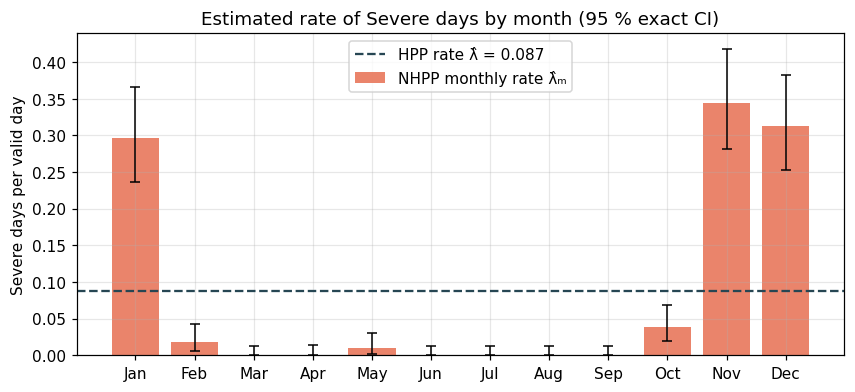

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(12)
r = month_rates.rate_per_day
ax.bar(x, r, color="#e76f51", alpha=0.85, label="NHPP monthly rate λ̂ₘ")
ax.errorbar(x, r, yerr=[r - month_rates.ci_lo, month_rates.ci_hi - r], fmt="none", ecolor="k", capsize=3, lw=1)
ax.axhline(lam, color="#264653", ls="--", label=f"HPP rate λ̂ = {lam:.3f}")
ax.set_xticks(x, MONTHS)
ax.set(title="Estimated rate of Severe days by month (95 % exact CI)", ylabel="Severe days per valid day")
ax.legend()
fig.savefig(FIG / "A08_monthly_rates.png")
plt.show()

### Likelihood-ratio tests and model comparison
Log-likelihood of the cell counts: $\ell = \sum_{y,m} \log \text{Poisson}(n_{ym};\ \lambda_m T_{ym})$.
HPP (1 parameter) ⊂ seasonal NHPP (4) ⊂ monthly NHPP (12). $2(\ell_1-\ell_0) \sim \chi^2_{\Delta k}$ under the smaller model.

In [8]:
lam_m = dict(zip(range(1, 13), month_rates.rate_per_day))
lam_s = season_rates.rate_per_day.to_dict()
season_of = study.groupby("month").season.first().to_dict()
cells["mu_month"] = cells.month.map(lam_m) * cells["T"]
cells["mu_season"] = cells.month.map(season_of).map(lam_s) * cells["T"]

def loglik(n, mu):
    mu = np.maximum(mu, 1e-12)
    return float(stats.poisson.logpmf(n, mu).sum())

models = {"HPP": ("mu_hpp", 1, 1), "Seasonal NHPP": ("mu_season", 4, n_active(lam_s)),
          "Monthly NHPP": ("mu_month", 12, n_active(lam_m))}
comp = pd.DataFrame({name: {"params": k_, "loglik": loglik(cells.n, cells[col])}
                     for name, (col, k_, _) in models.items()}).T
comp["AIC"] = 2 * comp.params - 2 * comp.loglik
disp = [pearson_dispersion(cells.n, cells[col], ka) for col, _, ka in models.values()]
comp["dispersion"] = [d[0] for d in disp]
comp["dispersion p"] = [d[3] for d in disp]
display(comp.round(2))

for small, big in [("HPP", "Seasonal NHPP"), ("HPP", "Monthly NHPP"), ("Seasonal NHPP", "Monthly NHPP")]:
    lr = 2 * (comp.loc[big, "loglik"] - comp.loc[small, "loglik"])
    dk = int(comp.loc[big, "params"] - comp.loc[small, "params"])
    print(f"LRT {small:>13} vs {big:<13}: LR = {lr:7.1f}, df = {dk:2d}, p = {stats.chi2.sf(lr, dk):.1e}")
RESULTS["model_comparison"] = comp.reset_index(names="model").to_dict("records")
RESULTS["month_rates"] = month_rates.reset_index(names="month").to_dict("records")
RESULTS["season_rates"] = season_rates.reset_index().to_dict("records")

,params,loglik,AIC,dispersion,dispersion p
HPP,1.0,-462.78,927.56,8.11,0.0
Seasonal NHPP,4.0,-217.66,443.33,3.45,0.0
Monthly NHPP,12.0,-122.90,269.79,1.77,0.0


LRT           HPP vs Seasonal NHPP: LR =   490.2, df =  3, p = 6.2e-106
LRT           HPP vs Monthly NHPP : LR =   679.8, df = 11, p = 1.2e-138
LRT Seasonal NHPP vs Monthly NHPP : LR =   189.5, df =  8, p = 1.0e-36


### Cumulative counts: data vs HPP vs NHPP

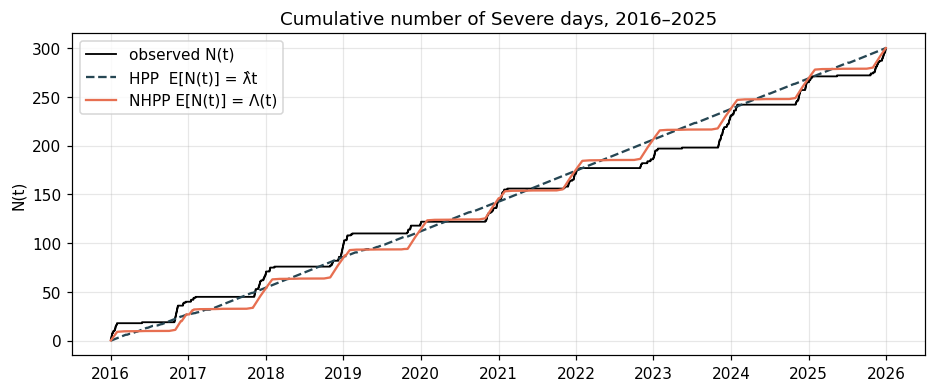

In [9]:
valid_cum = study.valid.cumsum().to_numpy()
Lambda_nhpp = np.cumsum(study.month.map(lam_m).to_numpy() * study.valid.to_numpy())
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.step(study.index, study.event.cumsum(), where="post", color="k", lw=1.2, label="observed N(t)")
ax.plot(study.index, lam * valid_cum, color="#264653", ls="--", label="HPP  E[N(t)] = λ̂t")
ax.plot(study.index, Lambda_nhpp, color="#e76f51", label="NHPP E[N(t)] = Λ(t)")
ax.set(title="Cumulative number of Severe days, 2016–2025", ylabel="N(t)")
ax.legend()
fig.savefig(FIG / "A09_cumulative_counts.png")
plt.show()

**Reading.** The monthly NHPP follows the staircase shape (flat in summer and monsoon, steep in Nov–Jan)
and is strongly preferred by both the likelihood-ratio test and AIC (AIC 928 → 443 → 270).
Severe days occur from October to February — 94 % of them in **November–January**, at a rate of about
one day in three — plus 3 isolated days in May. Apart from those, March–September had no Severe day in ten years.

Seasonality explains most of the excess variance (dispersion 8.1 → 1.8), but 1.8 is still above 1
(p < 0.001): within the same month, counts still vary more than a Poisson process allows. The next
sections look at two possible reasons: differences between **years** and **clustering** of days.

## 3. Has the rate changed over the years?
Poisson regression (generalised linear model) on the cell counts with a log-exposure offset:
$\log E[n_{ym}] = \log T_{ym} + \alpha_m + \beta_y$. Only months that ever have a Severe day are used.
Because the counts are overdispersed, the test is also repeated with the quasi-Poisson scale.

In [10]:
active = [m for m in range(1, 13) if lam_m[m] > 0]
act = cells[cells.month.isin(active)].copy()
act["year_c"] = act.year - 2020
off = np.log(act["T"])
fam = sm.families.Poisson()
m_month = smf.glm("n ~ C(month)", data=act, family=fam, offset=off).fit()
m_year = smf.glm("n ~ C(month) + C(year)", data=act, family=fam, offset=off).fit()
m_trend = smf.glm("n ~ C(month) + year_c", data=act, family=fam, offset=off).fit(scale="X2")
phi = m_year.pearson_chi2 / m_year.df_resid
lr_year = 2 * (m_year.llf - m_month.llf)
dfy = int(m_month.df_resid - m_year.df_resid)
print(f"active months: {[MONTHS[m - 1] for m in active]}")
print(f"year effect: LR = {lr_year:.1f}, df = {dfy}, p = {stats.chi2.sf(lr_year, dfy):.1e}")
print(f"residual dispersion phi = {phi:.2f}; quasi-Poisson F = {lr_year / dfy / phi:.2f}, "
      f"p = {stats.f.sf(lr_year / dfy / phi, dfy, m_year.df_resid):.3f}")
b, se = m_trend.params["year_c"], m_trend.bse["year_c"]
print(f"linear trend: {100 * (np.exp(b) - 1):+.1f}% per year, 95% CI "
      f"[{100 * (np.exp(b - 1.96 * se) - 1):+.1f}%, {100 * (np.exp(b + 1.96 * se) - 1):+.1f}%] (quasi-Poisson SE)")
RESULTS["year_effect"] = {"LR": lr_year, "df": dfy, "p_poisson": stats.chi2.sf(lr_year, dfy), "phi": phi,
                          "p_quasi": stats.f.sf(lr_year / dfy / phi, dfy, m_year.df_resid),
                          "trend_pct_per_year": 100 * (np.exp(b) - 1),
                          "trend_ci": [100 * (np.exp(b - 1.96 * se) - 1), 100 * (np.exp(b + 1.96 * se) - 1)]}

active months: ['Jan', 'Feb', 'May', 'Oct', 'Nov', 'Dec']
year effect: LR = 24.7, df = 9, p = 3.3e-03
residual dispersion phi = 1.54; quasi-Poisson F = 1.78, p = 0.099
linear trend: -0.4% per year, 95% CI [-5.6%, +5.0%] (quasi-Poisson SE)


,O,E,ratio,lo,hi
year,,,,,
2016,40,27.02,1.48,1.06,2.02
2017,29,26.70,1.09,0.73,1.56
2018,29,31.22,0.93,0.62,1.33
2019,22,29.31,0.75,0.47,1.14
2020,23,31.24,0.74,0.47,1.10
2021,28,29.74,0.94,0.63,1.36
2022,16,31.22,0.51,0.29,0.83
2023,44,31.22,1.41,1.02,1.89
2024,34,31.09,1.09,0.76,1.53


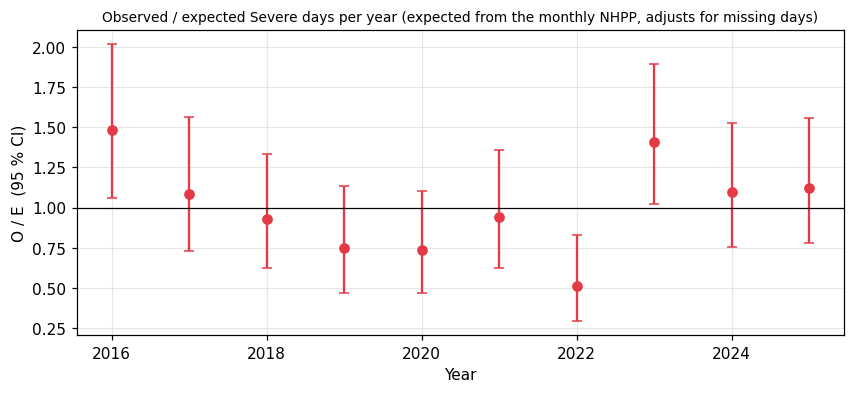

In [11]:
yr = cells.groupby("year").agg(O=("n", "sum"), E=("mu_month", "sum"))
yr[["ratio", "lo", "hi"]] = np.array([rate_ci(o, e) for o, e in zip(yr.O, yr.E)])
display(yr.round(2))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.errorbar(yr.index, yr.ratio, yerr=[yr.ratio - yr.lo, yr.hi - yr.ratio], fmt="o", color="#e63946", capsize=3)
ax.axhline(1, color="k", lw=0.8)
ax.set(title="Observed / expected Severe days per year (expected from the monthly NHPP, adjusts for missing days)",
       ylabel="O / E  (95 % CI)", xlabel="Year")
ax.title.set_fontsize(9)
fig.savefig(FIG / "A10_yearly_ratio.png")
plt.show()
RESULTS["yearly_OE"] = yr.reset_index().to_dict("records")

**Reading.** After adjusting for season and missing days, years differ somewhat (2022 was unusually clean,
O/E = 0.51; 2023 unusually bad, O/E = 1.41). With a plain Poisson model this year effect is significant
(p = 0.003), but once the extra variance is accounted for (quasi-Poisson) it is not (p = 0.10), and there is
**no detectable trend**: −0.4 % per year, 95 % CI [−5.6 %, +5.0 %]. Ten years of data cannot show that
Severe days are becoming less frequent at this station.

## 4. Clustering: Severe episodes and the compound Poisson process
An **episode** is a maximal run of consecutive Severe days (a missing day ends a run).

112 episodes, mean length 2.68 days, longest 17 days; geometric q_hat = 0.627
E[L^2]/E[L]: observed 5.32, geometric (1+q)/(1-q) = 4.36
geometric GOF (lengths 1..5, 6+ pooled): chi2 = 11.94, p = 0.018


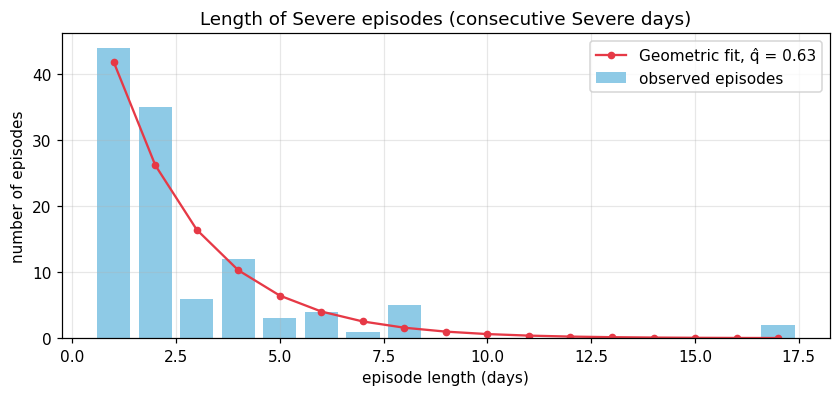

In [12]:
def find_episodes(d):
    """Return (onset dates, lengths) of runs of consecutive event days on the daily grid."""
    e = d.event.to_numpy()
    starts = np.flatnonzero(e & ~np.r_[False, e[:-1]])
    ends = np.flatnonzero(e & ~np.r_[e[1:], False])
    return d.index[starts], ends - starts + 1

onsets, L = find_episodes(study)
study["onset"] = study.index.isin(onsets)
Lbar = L.mean()
q_hat = 1 - 1 / Lbar
print(f"{len(L)} episodes, mean length {Lbar:.2f} days, longest {L.max()} days; geometric q_hat = {q_hat:.3f}")
print(f"E[L^2]/E[L]: observed {np.mean(L ** 2) / Lbar:.2f}, geometric (1+q)/(1-q) = {(1 + q_hat) / (1 - q_hat):.2f}")

kk = np.arange(1, L.max() + 1)
obs_L = np.bincount(L, minlength=L.max() + 1)[1:]
exp_L = len(L) * (1 - q_hat) * q_hat ** (kk - 1)
# chi-square goodness of fit: lengths 1..cut separately, longer ones pooled, every expected count >= 5
tail = len(L) * q_hat ** kk                      # expected number of episodes longer than k
cut = max(k_ for k_ in kk if exp_L[k_ - 1] >= 5 and tail[k_ - 1] >= 5)
o_g = np.r_[obs_L[:cut], obs_L[cut:].sum()]
e_g = np.r_[exp_L[:cut], tail[cut - 1]]
chi_L = stats.chisquare(o_g, e_g, ddof=1)
print(f"geometric GOF (lengths 1..{cut}, {cut + 1}+ pooled): chi2 = {chi_L.statistic:.2f}, p = {chi_L.pvalue:.3f}")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(kk, obs_L, color="#8ecae6", label="observed episodes")
ax.plot(kk, exp_L, "o-", color="#e63946", ms=4, label=f"Geometric fit, q̂ = {q_hat:.2f}")
ax.set(title="Length of Severe episodes (consecutive Severe days)", xlabel="episode length (days)", ylabel="number of episodes")
ax.legend()
fig.savefig(FIG / "A11_episode_lengths.png")
plt.show()

In [13]:
onset_rates = rates_by(study.assign(event=study.onset), "month", range(1, 13))
mu_m = dict(zip(range(1, 13), onset_rates.rate_per_day))
oc = cell_table(study, "onset")
oc["mu"] = oc.month.map(mu_m) * oc["T"]
D_on = pearson_dispersion(oc.n, oc.mu, n_active(mu_m))
D_nhpp = comp.loc["Monthly NHPP", "dispersion"]
print(f"episode onsets: dispersion under monthly NHPP = {D_on[0]:.2f} (p = {D_on[3]:.3f})")
print(f"Severe days: dispersion under monthly NHPP = {D_nhpp:.2f}; "
      f"compound-Poisson prediction E[L^2]/E[L] = {np.mean(L ** 2) / Lbar:.2f}")
RESULTS["episodes"] = {"n": int(len(L)), "mean_length": Lbar, "max_length": int(L.max()), "q_hat": q_hat,
                       "EL2_over_EL": float(np.mean(L ** 2) / Lbar), "geom_chi2": chi_L.statistic,
                       "geom_p": chi_L.pvalue, "onset_dispersion": D_on[0], "onset_dispersion_p": D_on[3]}
RESULTS["onset_rates"] = onset_rates.reset_index().to_dict("records")

episode onsets: dispersion under monthly NHPP = 0.89 (p = 0.707)
Severe days: dispersion under monthly NHPP = 1.77; compound-Poisson prediction E[L^2]/E[L] = 5.32


### Time-rescaling check of the three models
If a point process has intensity $\lambda(t)$, then $\tau_k = \Lambda(S_k) - \Lambda(S_{k-1})$ are iid Exp(1)
(time-rescaling theorem). We compare: (i) Severe days under the HPP, (ii) Severe days under the monthly NHPP,
(iii) **episode onsets** under their own monthly NHPP.

HPP – Severe days        n = 299  KS D = 0.509  p = 1.95e-72
NHPP – Severe days       n = 299  KS D = 0.227  p = 4.70e-14
NHPP – episode onsets    n = 111  KS D = 0.165  p = 4.02e-03


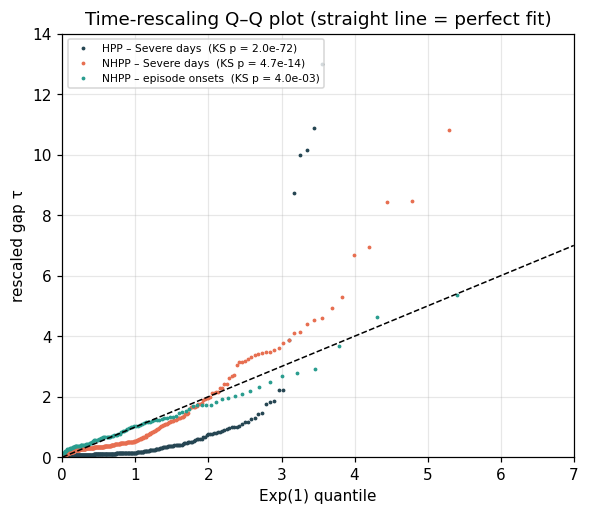

In [14]:
checks = {
    "HPP – Severe days": np.diff(rescaled_times(study, {m: lam for m in range(1, 13)}, "event")),
    "NHPP – Severe days": np.diff(rescaled_times(study, lam_m, "event")),
    "NHPP – episode onsets": np.diff(rescaled_times(study, mu_m, "onset")),
}
fig, ax = plt.subplots(figsize=(6, 5))
for (name, tau), col in zip(checks.items(), ["#264653", "#e76f51", "#2a9d8f"]):
    ks = stats.kstest(tau, "expon")
    exp_qq(ax, tau, f"{name}  (KS p = {ks.pvalue:.1e})", col)
    print(f"{name:<24} n = {len(tau):3d}  KS D = {ks.statistic:.3f}  p = {ks.pvalue:.2e}")
    RESULTS.setdefault("time_rescaling", {})[name] = {"n": len(tau), "ks_D": ks.statistic, "ks_p": ks.pvalue}
lim = 7
ax.plot([0, lim], [0, lim], "k--", lw=1)
ax.set(xlim=(0, lim), ylim=(0, lim * 2), xlabel="Exp(1) quantile", ylabel="rescaled gap τ",
       title="Time-rescaling Q–Q plot (straight line = perfect fit)")
ax.legend(fontsize=7, loc="upper left")
fig.savefig(FIG / "A12_time_rescaling.png")
plt.show()

**Reading.**
* Rescaling by the monthly NHPP removes the seasonal effect (KS distance 0.51 → 0.23), but Severe *days*
  are still not Poisson: there are far too many very short rescaled gaps, i.e. back-to-back Severe days.
* Treating each **episode** as one event works much better: episode onsets have a dispersion index of 0.89
  (p = 0.71, consistent with Poisson) and the KS distance falls to 0.17. The remaining misfit (p = 0.004)
  is expected because a new episode cannot start while one is already running ("dead time").
* Episode lengths are roughly geometric (mean 2.7 days, P(stay Severe) ≈ 0.63) but with a heavier tail
  (episodes up to 17 days; χ² p = 0.02).
* A geometric run length is exactly what a two-state Markov chain produces (stay Severe with probability $q$).
  This links directly to the Markov-chain model (Member B).

## 5. Simulation of the three fitted models
Each model is simulated 2000 times on the same 3653-day calendar (only valid days can carry events, as in the data).
* HPP: daily counts $\sim$ Poisson$(\hat\lambda)$.
* Monthly NHPP: daily counts $\sim$ Poisson$(\hat\lambda_{m(d)})$.
* Compound NHPP: episode onsets $\sim$ Poisson$(\hat\mu_{m(d)})$ per day, each adding Geometric$(1-\hat q)$ Severe days.

In [15]:
valid_mask = study.valid.to_numpy()
lam_hpp_d = np.where(valid_mask, lam, 0.0)
lam_nhpp_d = study.month.map(lam_m).to_numpy() * valid_mask
mu_d = study.month.map(mu_m).to_numpy() * valid_mask


def simulate(model, lam_d=None, mu_d_=None, q=None, n=N_SIM):
    if model == "compound":
        K = rng.poisson(mu_d_, size=(n, len(mu_d_)))
        extra = rng.negative_binomial(np.maximum(K, 1), 1 - q)
        return np.where(K > 0, K + extra, 0)
    return rng.poisson(lam_d, size=(n, len(lam_d)))


sims = {"HPP": simulate("p", lam_hpp_d), "Monthly NHPP": simulate("p", lam_nhpp_d),
        "Compound NHPP": simulate("compound", mu_d_=mu_d, q=q_hat)}

# one-hot map day -> (year, month) cell, to aggregate simulated days into monthly counts
cell_key = pd.MultiIndex.from_arrays([study.year, study.month])
cell_idx = pd.MultiIndex.from_frame(cells[["year", "month"]]).get_indexer(cell_key)
M = np.zeros((len(study), len(cells)))
ok = cell_idx >= 0
M[np.flatnonzero(ok), cell_idx[ok]] = 1
act_cells = cells.mu_month.to_numpy() > 0
mu_ref = cells.mu_month.to_numpy()[act_cells]
k_ref = n_active(lam_m)

def sim_dispersion(daily_counts):
    cc = (daily_counts @ M)[:, act_cells]
    return ((cc - mu_ref) ** 2 / mu_ref).sum(axis=1) / (len(mu_ref) - k_ref)

obs_D = pearson_dispersion(cells.n, cells.mu_month, k_ref)[0]
sim_summary = {}
for name, s in sims.items():
    Dsim = sim_dispersion(s)
    tot = s.sum(axis=1)
    sim_summary[name] = {"total_mean": tot.mean(), "total_q025": np.quantile(tot, 0.025), "total_q975": np.quantile(tot, 0.975),
                         "D_mean": Dsim.mean(), "D_q025": np.quantile(Dsim, 0.025), "D_q975": np.quantile(Dsim, 0.975),
                         "P(D_sim >= D_obs)": np.mean(Dsim >= obs_D)}
    sims[name] = (s, Dsim)
sim_df = pd.DataFrame(sim_summary).T
print(f"observed total = {N}, observed dispersion (vs monthly NHPP means) = {obs_D:.2f}")
display(sim_df.round(3))
RESULTS["simulation"] = sim_df.reset_index(names="model").to_dict("records")
RESULTS["simulation_observed_D"] = obs_D

observed total = 300, observed dispersion (vs monthly NHPP means) = 1.77


,total_mean,total_q025,total_q975,D_mean,D_q025,D_q975,P(D_sim >= D_obs)
HPP,299.594,265.975,334.0,10.665,7.030,15.824,1.000
Monthly NHPP,300.668,266.000,335.0,1.118,0.697,1.733,0.021
Compound NHPP,299.239,229.975,375.0,8.110,3.035,18.215,1.000


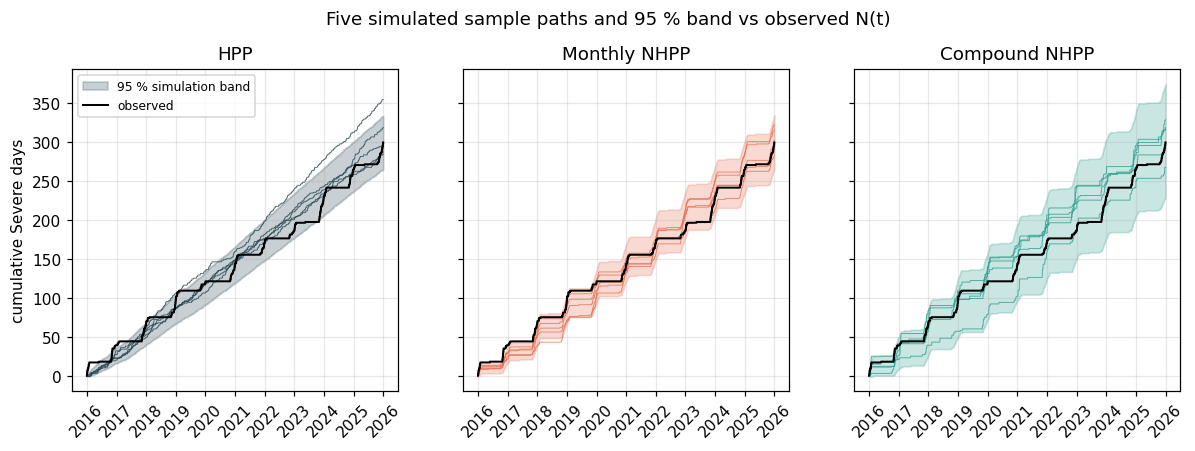

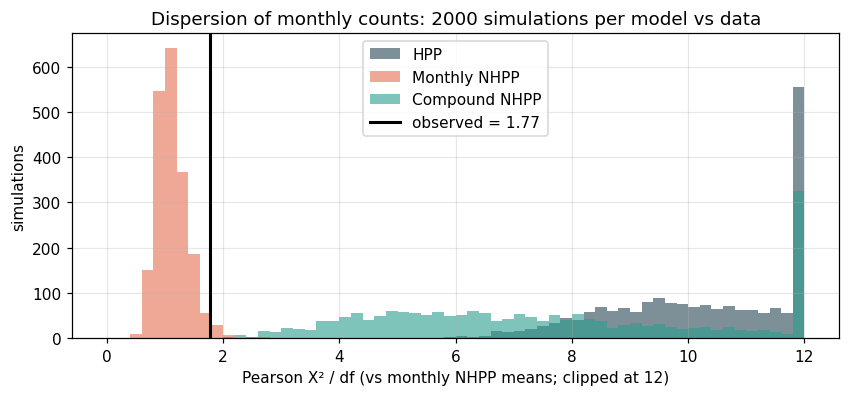

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
obs_cum = study.event.cumsum().to_numpy()
for ax, (name, (s, _)), col in zip(axes, sims.items(), ["#264653", "#e76f51", "#2a9d8f"]):
    cum = np.cumsum(s, axis=1)
    lo, hi = np.quantile(cum, [0.025, 0.975], axis=0)
    ax.fill_between(study.index, lo, hi, color=col, alpha=0.25, label="95 % simulation band")
    for i in range(5):
        ax.plot(study.index, cum[i], color=col, lw=0.6, alpha=0.8)
    ax.step(study.index, obs_cum, where="post", color="k", lw=1.3, label="observed")
    ax.set_title(name)
    ax.tick_params(axis="x", labelrotation=45)
axes[0].set_ylabel("cumulative Severe days")
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Five simulated sample paths and 95 % band vs observed N(t)", y=1.02)
fig.savefig(FIG / "A13_simulated_paths.png")
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.6))
for (name, (_, Dsim)), col in zip(sims.items(), ["#264653", "#e76f51", "#2a9d8f"]):
    ax.hist(np.clip(Dsim, 0, 12), bins=60, range=(0, 12), alpha=0.6, color=col, label=name)
ax.axvline(obs_D, color="k", lw=2, label=f"observed = {obs_D:.2f}")
ax.set(title="Dispersion of monthly counts: 2000 simulations per model vs data",
       xlabel="Pearson X² / df (vs monthly NHPP means; clipped at 12)", ylabel="simulations")
ax.legend()
fig.savefig(FIG / "A14_simulated_dispersion.png")
plt.show()

**Reading.** All three models reproduce the 10-year total (≈ 300). The difference is in the *variability*
of the monthly counts:
* HPP: simulated dispersion ≈ 10.7 — completely wrong, because it ignores the season.
* Monthly NHPP: simulated dispersion ≈ 1.1, observed 1.77, which is above 97.9 % of simulations. The NHPP is
  **slightly too regular**.
* Compound NHPP: simulated dispersion ≈ 8.1 — **far too variable**. Independent geometric episodes can pile
  up in one month, but in reality a month has only ~30 days and a new episode cannot start inside an old one,
  so real clustering is self-limiting.

So the truth lies between the two: clustering is strong from day to day, but it averages out to only
mild extra variance at the monthly scale.

## 6. Out-of-sample validation
Fit every model on **2016–2022** only, then predict the number of Severe days in each later year
(2023, 2024, 2025 and Jan–Sep 2026) and in each later month. A good model's 95 % prediction intervals
should contain the observed value about 95 % of the time.

In [17]:
train = study.loc[:TRAIN_END]
test = pd.concat([study.loc[TRAIN_END:].iloc[1:], holdout])
lam_tr = train.event.sum() / train.valid.sum()
lam_m_tr = {m: train[train.month == m].event.sum() / train[train.month == m].valid.sum() for m in range(1, 13)}
on_tr, L_tr = find_episodes(train)
train_on = train.index.isin(on_tr)
mu_m_tr = {m: train_on[train.month == m].sum() / train[train.month == m].valid.sum() for m in range(1, 13)}
q_tr = 1 - 1 / L_tr.mean()

tv = test.valid.to_numpy()
pred_inputs = {
    "HPP": simulate("p", np.where(tv, lam_tr, 0.0)),
    "Monthly NHPP": simulate("p", test.month.map(lam_m_tr).to_numpy() * tv),
    "Compound NHPP": simulate("compound", mu_d_=test.month.map(mu_m_tr).to_numpy() * tv, q=q_tr),
}
test_years = test.year.to_numpy()
rows = []
for y in np.unique(test_years):
    obs_y = int(test.event[test_years == y].sum())
    row = {"year": f"{y}" + (" (Jan–Sep)" if y == 2026 else ""), "observed": obs_y}
    for name, s in pred_inputs.items():
        t_y = s[:, test_years == y].sum(axis=1)
        lo, hi = np.quantile(t_y, [0.025, 0.975])
        row[f"{name} mean"] = round(t_y.mean(), 1)
        row[f"{name} 95% PI"] = f"[{lo:.0f}, {hi:.0f}]"
        row[f"{name} inside"] = bool(lo <= obs_y <= hi)
    rows.append(row)
oos_year = pd.DataFrame(rows).set_index("year")
display(oos_year)

# month-level coverage and log predictive score
tcells = cell_table(test)
tkey = pd.MultiIndex.from_arrays([test.year, test.month])
tidx = pd.MultiIndex.from_frame(tcells[["year", "month"]]).get_indexer(tkey)
Mt = np.zeros((len(test), len(tcells)))
okt = tidx >= 0
Mt[np.flatnonzero(okt), tidx[okt]] = 1
score_rows = {}
for name, s in pred_inputs.items():
    cc = s @ Mt
    lo, hi = np.quantile(cc, [0.025, 0.975], axis=0)
    inside = (tcells.n.to_numpy() >= lo) & (tcells.n.to_numpy() <= hi)
    # predictive probability of the observed count, with add-half smoothing for unseen values
    p_obs = ((cc == tcells.n.to_numpy()).sum(axis=0) + 0.5) / (N_SIM + 1)
    score_rows[name] = {"95% PI coverage (months)": inside.mean(), "mean log score": np.log(p_obs).mean(),
                        "mean abs error": np.abs(cc.mean(axis=0) - tcells.n.to_numpy()).mean()}
oos_month = pd.DataFrame(score_rows).T
display(oos_month.round(3))
RESULTS["oos_year"] = oos_year.reset_index().to_dict("records")
RESULTS["oos_month"] = oos_month.reset_index(names="model").to_dict("records")
RESULTS["train_params"] = {"lambda": lam_tr, "q": q_tr, "lambda_m": lam_m_tr, "mu_m": mu_m_tr}

,observed,HPP mean,HPP 95% PI,HPP inside,Monthly NHPP mean,Monthly NHPP 95% PI,Monthly NHPP inside,Compound NHPP mean,Compound NHPP 95% PI,Compound NHPP inside
year,,,,,,,,,,
2023,44,28.4,"[18, 39]",False,28.5,"[19, 40]",False,27.8,"[9, 51]",True
2024,34,28.3,"[19, 39]",True,28.2,"[18, 40]",True,28.2,"[10, 53]",True
2025,35,28.2,"[19, 39]",True,28.7,"[18, 39]",True,28.3,"[9, 54]",True
2026 (Jan–Sep),7,21.1,"[13, 31]",False,10.1,"[5, 17]",True,10.0,"[0, 25]",True


,95% PI coverage (months),mean log score,mean abs error
HPP,0.800,-3.355,3.764
Monthly NHPP,0.956,-0.990,1.093
Compound NHPP,0.978,-1.050,1.316


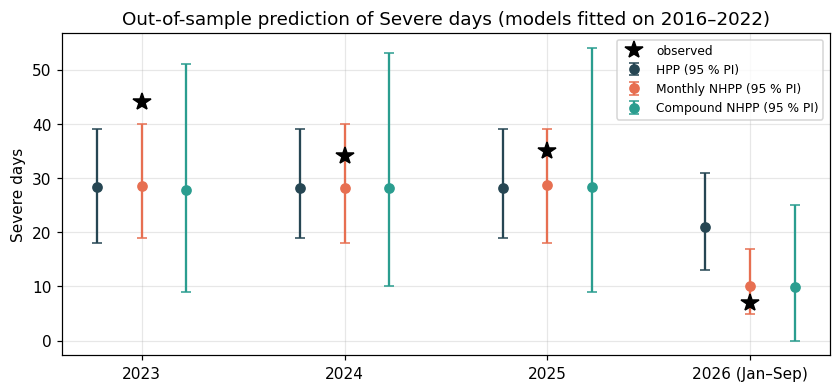

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.8))
labels = list(oos_year.index)
xx = np.arange(len(labels))
for j, (name, s) in enumerate(pred_inputs.items()):
    tot = np.array([s[:, test_years == y].sum(axis=1) for y in np.unique(test_years)]).T
    lo, hi = np.quantile(tot, [0.025, 0.975], axis=0)
    ax.errorbar(xx + (j - 1) * 0.22, tot.mean(axis=0), yerr=[tot.mean(axis=0) - lo, hi - tot.mean(axis=0)],
                fmt="o", capsize=3, color=["#264653", "#e76f51", "#2a9d8f"][j], label=f"{name} (95 % PI)")
ax.plot(xx, oos_year.observed, "k*", ms=12, label="observed")
ax.set_xticks(xx, labels)
ax.set(title="Out-of-sample prediction of Severe days (models fitted on 2016–2022)", ylabel="Severe days")
ax.legend(fontsize=8)
fig.savefig(FIG / "A15_out_of_sample.png")
plt.show()

**Reading.**
* The HPP fails: it predicts 21 Severe days for Jan–Sep 2026 (observed 7) because it ignores the season,
  and its monthly intervals cover only 80 % of the test months.
* The **monthly NHPP is the best predictive model**: its 95 % intervals cover 95.6 % of test months
  (close to the nominal 95 %), and it has the best log score and the smallest error (≈ 1.1 days per month).
* Its one miss is the year **2023** (44 observed vs interval [19, 40]). This is the year-to-year extra variance
  seen in Section 3; a single bad winter is more extreme than a pure Poisson process expects.
* The compound model covers every test year, but only because its intervals are about twice as wide.

## 7. Sensitivity: threshold 120 µg/m³ ("Very Poor" or worse)

In [19]:
def quick_summary(c):
    d = study.assign(event=study.valid & (study.pm25 > c))
    ct = cell_table(d)
    n_, T_ = int(d.event.sum()), int(d.valid.sum())
    lm = {m: d[d.month == m].event.sum() / d[d.month == m].valid.sum() for m in range(1, 13)}
    mu_h, mu_n = n_ / T_ * ct["T"], ct.month.map(lm) * ct["T"]
    _, Lc = find_episodes(d)
    return {"threshold": c, "events": n_, "rate/day": n_ / T_, "per year": n_ / T_ * 365.25,
            "HPP dispersion": pearson_dispersion(ct.n, mu_h, 1)[0],
            "NHPP dispersion": pearson_dispersion(ct.n, mu_n, n_active(lm))[0],
            "LR HPP vs NHPP": 2 * (loglik(ct.n, mu_n) - loglik(ct.n, mu_h)),
            "episodes": len(Lc), "mean episode length": Lc.mean()}

sens = pd.DataFrame([quick_summary(c) for c in (120, 250)]).set_index("threshold")
display(sens.round(3))
RESULTS["sensitivity"] = sens.reset_index().to_dict("records")

,events,rate/day,per year,HPP dispersion,NHPP dispersion,LR HPP vs NHPP,episodes,mean episode length
threshold,,,,,,,,
120,1186,0.346,126.293,11.964,2.409,1401.163,160,7.412
250,300,0.087,31.946,8.109,1.772,679.771,112,2.679


**Reading.** With the lower threshold (120 µg/m³) events are four times as common (≈ 126 days/year) and
episodes last ≈ 7.4 days instead of 2.7. That makes them much less "rare and independent", and the
dispersion after the seasonal fit is larger (2.4 vs 1.8). The Poisson framework suits the rarer Severe threshold better.

## Conclusions (Member A)
1. **Rate.** Over 2016–2025 R K Puram had 300 Severe days, λ̂ = 0.088 per day ≈ **32 per year**
   (95 % CI 28–36); the average wait between Severe days is 11.4 days.
2. **Seasonality dominates.** The rate is ≈ 0.30–0.34 per day in Nov–Jan and practically zero from March to
   September. The monthly NHPP beats the HPP decisively (LR = 680, df = 11, p ≈ 10⁻¹³⁸; AIC 928 → 270).
3. **No trend.** After adjusting for season there is no significant change over 2016–2025
   (−0.4 %/year, CI −5.6 % to +5.0 %); 2022 was unusually clean and 2023 unusually bad.
4. **Clustering.** 63 % of Severe days directly follow another Severe day (188 of 300). Episodes (mean 2.7 days)
   start like a Poisson process, but individual days are not independent. This motivates the Markov chain.
5. **Validation.** Fitted on 2016–2022, the monthly NHPP predicts 2023–Sep 2026 monthly counts with 95.6 %
   interval coverage, the best of the three models. It is a good model for *how many* Severe days a month
   or season will have, but not for *which* days, because it cannot capture persistence.

**Limitations.** Only one station; daily resolution (at most one event per day); 6 % of days missing, plus
5 % filled by interpolation; month-wise constant rates; meteorology (wind, temperature inversion,
stubble burning) is not used as a covariate.

**Extensions.** Weather covariates through Poisson regression; Cox (doubly stochastic) process for
year-to-year variation; self-exciting (Hawkes) process for clustering; several stations.

## 8. Save results and parameters for the team

In [20]:
def to_py(o):
    if isinstance(o, dict):
        return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_py(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return round(float(o), 6)
    if isinstance(o, np.bool_):
        return bool(o)
    return o

(RES / "A02_poisson_results.json").write_text(json.dumps(to_py(RESULTS), indent=2, default=str))
params = {"threshold_ugm3": THRESH, "fit_period": "2016-01-01..2025-12-31", "unit": "per valid day",
          "hpp_lambda": lam, "nhpp_lambda_by_month": {MONTHS[m - 1]: lam_m[m] for m in range(1, 13)},
          "episode_onset_rate_by_month": {MONTHS[m - 1]: mu_m[m] for m in range(1, 13)},
          "episode_continue_prob_q": q_hat}
(RES / "poisson_params.json").write_text(json.dumps(to_py(params), indent=2))
print("saved results/A02_poisson_results.json and results/poisson_params.json")

saved results/A02_poisson_results.json and results/poisson_params.json
